# Beyond the foreground screen: expanded interpretable ML benchmark

This notebook replays the executed 120-galaxy experiment and genuinely refits one frozen model on development data. Complete grouped candidate training, saved models, learning curves and final predictions were executed by the accompanying modules. Final predictions are read from the single evaluation receipt; this notebook never opens the final set for tuning or reruns its inference.

**Scope:** operational matched DR1 product contrasts, not validated physical dust labels or unique three-dimensional geometry. Actual LSST g / 2MASS J,Ks filters; fixed-rest-band z=0.1 distance experiment, provisional noise and Gaussian PSFs. The adaptive g-feature comparison is conditional on a common observed-Ks reference aperture.

**Final results (16 positive-dust galaxies; four final source controls):** recommended seeing-NIR MAE is 0.0734 mag for integrated g contrast, 0.0777 kpc for Ks ΔR50 and 0.0887 for Ks ΔC, versus median baselines 0.3003, 0.1282 and 0.1521. No positive GLAO gain interval excludes zero. GLAO improves native-clear morphology transfer, but does not establish extra dust-specific prediction information. Concentration is center-sensitive; physical-label source calibration is unresolved.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
O=Path.cwd()
if not (O/'expanded_models.py').exists(): O=O/'analysis_results/ml_expanded_20261028'
sys.path.insert(0,str(O.resolve()))
from freeze_guard import verify
from expanded_features import TARGETS
from expanded_models import frame,model
assert Path(sys.executable).resolve()==Path('/home/bahareh/miniforge3/envs/phd/bin/python').resolve()
print('Frozen receipt:',verify())
display(pd.Series(json.loads((O/'FINAL_EVALUATION_COMPLETED.json').read_text())))

Frozen receipt: 587aab56d39e6b29ad47f381c4b1440c8dd28eb52811ebc4ae3842b6fc220ce4


galaxies                                                                  20
models_retuned                                                         False
final_evaluation_count                                                     1
primary_policy             Exclude exact-zero projected-dust galaxies fro...
primary_galaxies                                                          16
source_control_galaxies                                                    4
rows                                                                  153600
freeze_sha256              587aab56d39e6b29ad47f381c4b1440c8dd28eb52811eb...
dtype: object

## Independent sampling and provenance
86/14/20 frozen galaxy assignments; all views and noise draws stay grouped. Exact-zero projected-dust objects are excluded from physical-task fitting/calibration/primary scoring under the predeclared policy and retained as source controls. Zero SFR is not used as the zero-dust criterion. The 94 new archives finished before this analysis; no duplicate download was launched.

In [2]:
inventory=pd.read_csv(O/'expanded_galaxy_inventory.csv')
display(inventory.groupby(['partition','zero_projected_dust'],dropna=False).size().rename('galaxies').to_frame())
display(pd.Series(json.loads((O/'POSTFINAL_VALIDATION.json').read_text())['checks']))
display(pd.read_csv(O/'recommended_settings.csv'))

galaxies
partition   zero_projected_dust          
development False                      74
            True                       12
final_test  False                      16
            True                        4
validation  False                      13
            True                        1

original_frozen_partitions_unchanged                                                               True
nonfinal_100_complete_finite_labels                                                                True
five_whole_galaxy_folds_disjoint                                                                   True
all_model_predictors_explicit_observable_allowlist                                                 True
g_observables_exact_same_between_modes                                                             True
maximum_padded_flux_loss                                                                            0.0
calibration_13_galaxies_rank12_per_target                                                          True
nonfinal_predictions_finite_and_controls_separate                                                  True
frozen_artifact_hash                                  587aab56d39e6b29ad47f381c4b1440c8dd28eb52811eb...
final20_disjoint_and_finite                                     

,target,family,config,value,MAE
0,A_Ks,summary_ridge,summary_ridge_10,10,0.012265
1,A_g_p50_1kpc,spatial_forest,spatial_forest_8,8,0.028710
2,dR50_Ks,summary_ridge,summary_ridge_1,1,0.059570
3,A_g,summary_ridge,summary_ridge_1,1,0.064437
4,A_g_IQR_1kpc,spatial_boost,spatial_boost_3,3,0.068226
5,dC_Ks,spatial_ridge,spatial_ridge_1,1,0.073041
6,dR50_g,spatial_ridge,spatial_ridge_1,1,0.250613
7,dC_g,spatial_boost,spatial_boost_2,2,0.253191


## Executed training replay: frozen recommended integrated-g model
The following fit uses development labels only. Feature preprocessing and target scaling are fit inside the estimator. No final label is loaded here. Its predictions are checked against the saved trained artifact on validation, without updating any model or hyperparameter.

In [3]:
import joblib
choice=pd.read_csv(O/'recommended_settings.csv').set_index('target').loc['A_g']
config=dict(family=choice.family,value=int(choice.value))
data=frame('seeing_NIR',partitions=['development','validation'])
fit=data[(data.partition=='development')&~data.zero_projected_dust]
validation=data[(data.partition=='validation')&~data.zero_projected_dust]
reproduced=model(config,'seeing_NIR').fit(fit,fit[TARGETS])
prediction=reproduced.predict(validation)
saved=joblib.load(O/'models'/f'adaptive_seeing_NIR_{choice.config}.joblib')
np.testing.assert_allclose(prediction,saved.predict(validation),rtol=1e-10,atol=1e-10)
j=TARGETS.index('A_g')
scores=pd.DataFrame(dict(subhalo_id=validation.subhalo_id,absolute_error=abs(prediction[:,j]-validation.A_g)))
print('Training galaxies:',fit.subhalo_id.nunique(),'validation galaxies:',validation.subhalo_id.nunique())
print('Reproduced validation Ag MAE:',scores.groupby('subhalo_id').absolute_error.mean().mean())

Training galaxies: 74 validation galaxies: 13
Reproduced validation Ag MAE: 0.05921075415806039


## One frozen final evaluation
The following tables are calculated from the saved per-orientation/per-draw predictions. MAE and RMSE weight galaxies equally; intervals resample galaxies, not pixels/views/noise. They condition on the fitted models and omit uncertain source-product systematics. The final source controls are excluded below and separately reported in the package.

In [4]:
summary=pd.read_csv(O/'recommended_performance.csv')
display(summary.query("evaluation=='final_test' and aperture=='adaptive'")[["scenario","target","n_galaxies","MAE","MAE_low","MAE_high","RMSE","bias","galaxy_coverage"]])
gains=pd.read_csv(O/'recommended_gains.csv')
display(gains.query("evaluation=='final_test' and aperture=='adaptive' and comparison=='seeing_minus_GLAO_MAE'")[["target","gain","low","high","fraction_galaxies_improved"]])

,scenario,target,n_galaxies,MAE,MAE_low,MAE_high,RMSE,bias,galaxy_coverage
0,GLAO_NIR,A_g_IQR_1kpc,16,0.070733,0.029130,0.137157,0.163947,-0.031962,0.8750
1,GLAO_NIR,dC_g,16,0.244532,0.166837,0.333444,0.327683,-0.092364,0.8125
2,GLAO_NIR,A_g_p50_1kpc,16,0.044119,0.015089,0.093333,0.139709,-0.024368,0.8125
3,GLAO_NIR,dC_Ks,16,0.088689,0.057911,0.125744,0.130596,0.004188,0.8750
4,GLAO_NIR,dR50_g,16,0.223605,0.156858,0.298508,0.316682,0.051561,0.9375
5,GLAO_NIR,A_Ks,16,0.012410,0.008518,0.016330,0.016317,0.003194,1.0000
6,GLAO_NIR,A_g,16,0.074077,0.049344,0.101164,0.109795,-0.040666,0.7500
7,GLAO_NIR,dR50_Ks,16,0.079875,0.048564,0.119198,0.118942,0.047791,0.9375
8,optical,A_g_IQR_1kpc,16,0.084757,0.031290,0.171355,0.209512,-0.031260,0.7500
9,optical,dC_g,16,0.356222,0.222117,0.522427,0.511307,-0.064419,0.6250


,target,gain,low,high,fraction_galaxies_improved
0,A_g_IQR_1kpc,0.003767,-0.000254,0.007900,0.7500
1,dC_g,-0.010598,-0.022541,0.002109,0.3125
8,A_g_p50_1kpc,-0.000025,-0.000498,0.000492,0.4375
12,dC_Ks,0.000036,-0.012097,0.012719,0.3750
13,dR50_g,-0.019239,-0.034117,-0.006227,0.2500
20,A_Ks,-0.000057,-0.000267,0.000157,0.3125
21,A_g,-0.000722,-0.005655,0.004196,0.5000
22,dR50_Ks,-0.002201,-0.007664,0.002617,0.6250


Wrote seven publication figures in PNG and PDF.


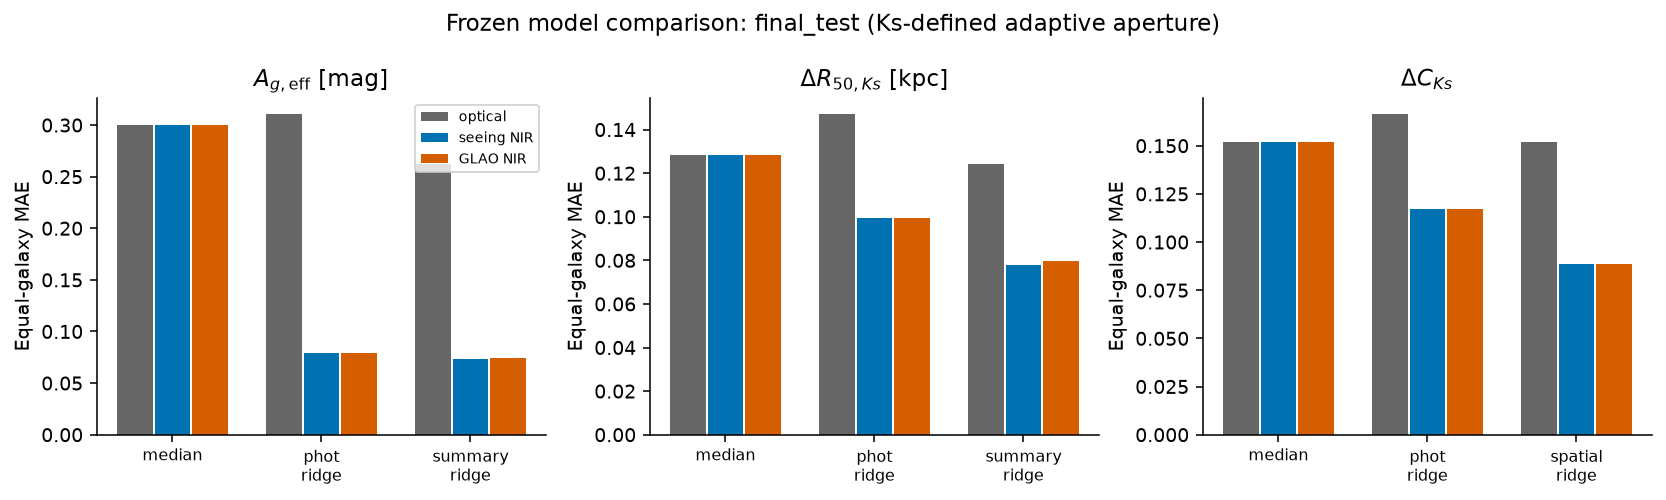

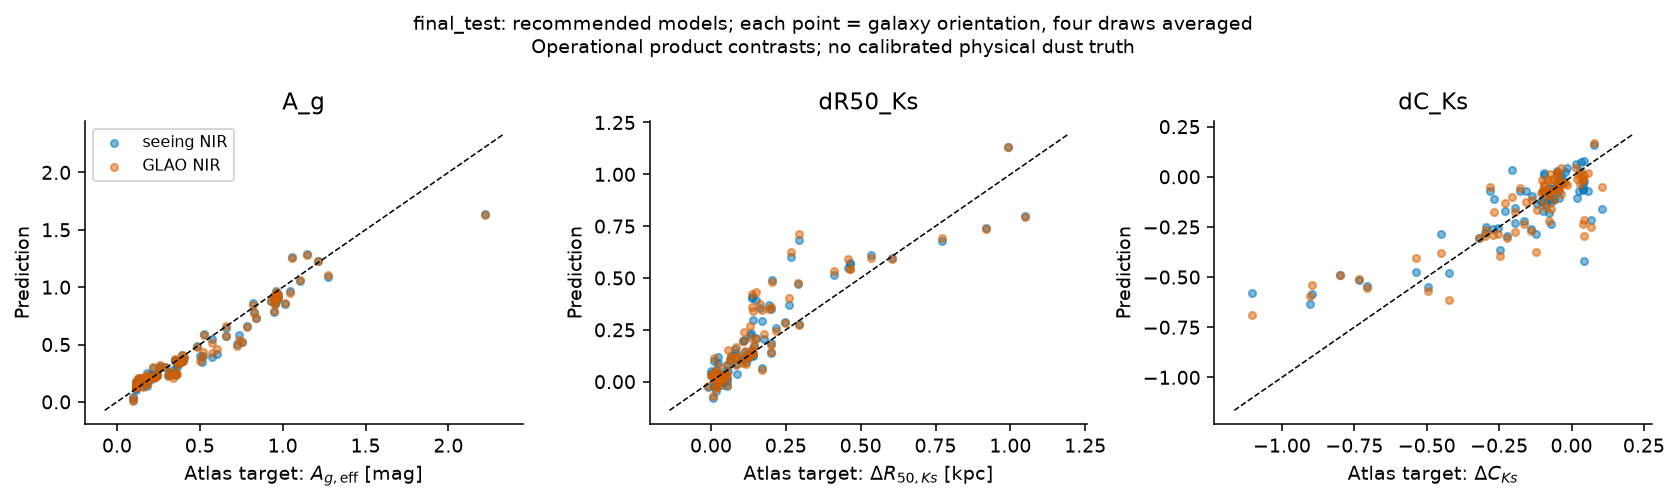

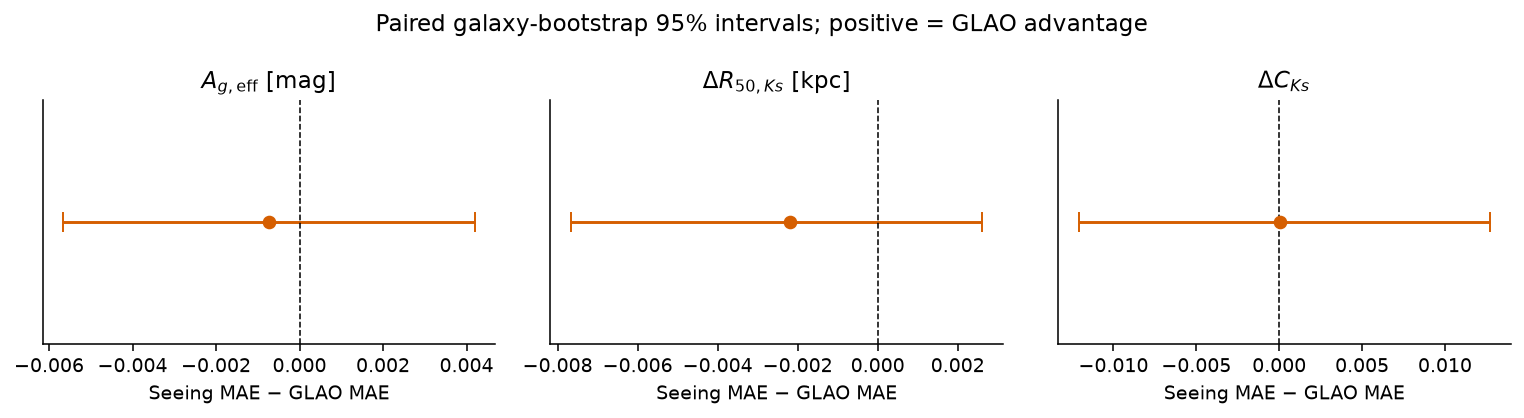

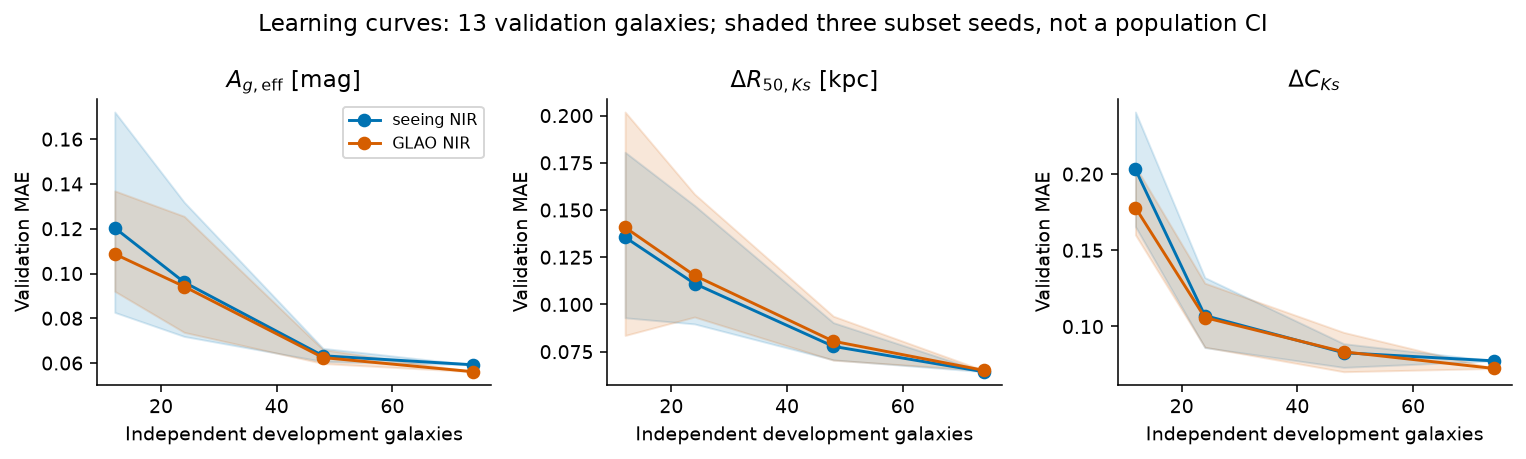

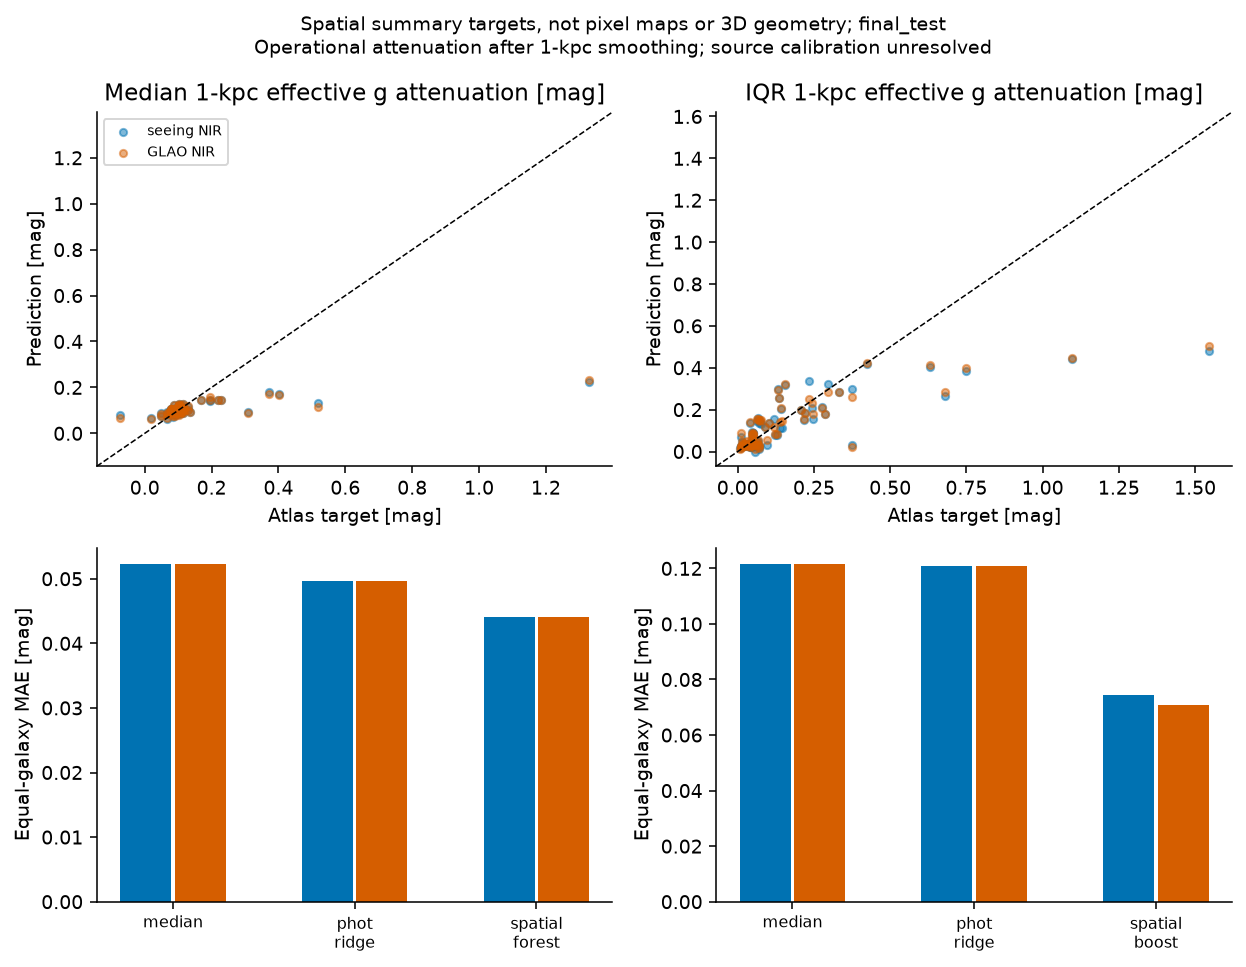

In [5]:
from figures import run as render_figures
render_figures()  # Editable Matplotlib code in figures.py; saved predictions only.
for name in ['model_and_observing_strategy_comparison','prediction_vs_atlas_target','paired_GLAO_gains','learning_curves','spatial_attenuation_statistics']:
    display(Image(filename=str(O/'figures'/(name+'.png'))))

## Morphology correction and systematics
Subtract predicted native dusty-minus-clear morphology from observed dusty morphology. The comparison to native clear therefore retains PSF/noise errors; it is not a general deconvolution or intrinsic-morphology estimator. Signed effective attenuation is preserved. The four historical zero-dust controls display a coherent ≈0.12-mag g contrast even in the full field; the cause remains unresolved, with possible analytic-versus-Monte-Carlo or spectral-integration operator differences. No empirical offset is subtracted.

In [6]:
display(summary.query("evaluation=='final_test' and aperture=='adaptive' and target in ['dR50_Ks','dC_Ks']")[["scenario","target","MAE","uncorrected_MAE","corrected_MAE"]])
display(pd.read_csv(O/'old_control_operator_envelopes.csv').query("aperture=='adaptive'")[["target","median","maximum_absolute"]])
display(pd.read_csv(O/'source_control_performance.csv').query("aperture=='adaptive' and scenario=='GLAO_NIR' and family=='median'"))

,scenario,target,MAE,uncorrected_MAE,corrected_MAE
3,GLAO_NIR,dC_Ks,0.088689,0.481380,0.329737
7,GLAO_NIR,dR50_Ks,0.079875,0.232470,0.086063
11,optical,dC_Ks,0.151944,0.705331,0.578309
15,optical,dR50_Ks,0.124010,0.298272,0.186980
19,seeing_NIR,dC_Ks,0.088725,0.705331,0.554413
23,seeing_NIR,dR50_Ks,0.077674,0.298272,0.120959


,target,median,maximum_absolute
0,A_g,0.122070,0.124333
1,A_Ks,0.020838,0.022591
2,A_g_p50_1kpc,0.111796,0.119068
3,A_g_IQR_1kpc,0.006450,0.012108
4,dR50_Ks,0.010454,0.037487
5,dC_Ks,0.014188,0.239817
6,dR50_g,0.011654,0.026122
7,dC_g,0.010267,0.122743


,evaluation,aperture,scenario,family,target,n_galaxies,MAE,MAE_low,MAE_high,RMSE,bias,point_coverage,galaxy_coverage,corrected_MAE,uncorrected_MAE
0,final_test_source_control,adaptive,GLAO_NIR,median,A_Ks,4,0.012619,0.010699,0.014392,0.012783,0.012619,1.0,1.0,NaN,NaN
1,final_test_source_control,adaptive,GLAO_NIR,median,A_g,4,0.254178,0.253116,0.255255,0.254181,0.254178,1.0,1.0,NaN,NaN
2,final_test_source_control,adaptive,GLAO_NIR,median,A_g_IQR_1kpc,4,0.087592,0.087120,0.088094,0.087663,0.087592,1.0,1.0,NaN,NaN
3,final_test_source_control,adaptive,GLAO_NIR,median,A_g_p50_1kpc,4,0.005313,0.003060,0.007714,0.006199,-0.005088,1.0,1.0,NaN,NaN
4,final_test_source_control,adaptive,GLAO_NIR,median,dC_Ks,4,0.113193,0.091414,0.143585,0.126951,-0.087229,1.0,1.0,0.375135,0.486902
5,final_test_source_control,adaptive,GLAO_NIR,median,dC_g,4,0.378575,0.350872,0.406278,0.382873,-0.378575,1.0,1.0,0.377312,0.781527
6,final_test_source_control,adaptive,GLAO_NIR,median,dR50_Ks,4,0.119927,0.114017,0.127483,0.120350,0.119927,1.0,1.0,0.025179,0.123966
7,final_test_source_control,adaptive,GLAO_NIR,median,dR50_g,4,0.502447,0.498699,0.506196,0.502548,0.502447,1.0,1.0,0.256787,0.256083
384,source_controls_source_control,adaptive,GLAO_NIR,median,A_Ks,13,0.012801,0.011471,0.014056,0.013038,0.012801,1.0,1.0,NaN,NaN
385,source_controls_source_control,adaptive,GLAO_NIR,median,A_g,13,0.253828,0.252666,0.255057,0.253838,0.253828,1.0,1.0,NaN,NaN


## Instrumental and aperture sensitivity
HAWK-I empirical widths are not ULTIMATE specifications. Fixed nominal D50 Moffat-wing, local-covariance, software-binning and radius/center experiments quantify conditional sensitivity; the full nonlocal empirical aperture-noise excess is not reproduced. O1-only stresses do not establish orientation-general benefits.

,evaluation,scenario,target,MAE
3,instrument_shift_A,GLAO_NIR,dC_Ks,0.123191
6,instrument_shift_A,GLAO_NIR,A_g,0.055404
7,instrument_shift_A,GLAO_NIR,dR50_Ks,0.098575
11,instrument_shift_A,seeing_NIR,dC_Ks,0.101871
14,instrument_shift_A,seeing_NIR,A_g,0.062799
15,instrument_shift_A,seeing_NIR,dR50_Ks,0.098796
19,instrument_shift_B,GLAO_NIR,dC_Ks,0.102567
22,instrument_shift_B,GLAO_NIR,A_g,0.056676
23,instrument_shift_B,GLAO_NIR,dR50_Ks,0.102330
27,instrument_shift_B,seeing_NIR,dC_Ks,0.113789


,evaluation,scenario,family,target,MAE
1,development_shift_high_mass_OOD,GLAO_NIR,phot_ridge,A_g,0.084917
4,development_shift_high_mass_OOD,GLAO_NIR,phot_ridge,dC_Ks,0.090784
6,development_shift_high_mass_OOD,GLAO_NIR,phot_ridge,dR50_Ks,0.125943
9,development_shift_high_mass_OOD,GLAO_NIR,spatial_ridge,A_g,0.089990
12,development_shift_high_mass_OOD,GLAO_NIR,spatial_ridge,dC_Ks,0.075989
14,development_shift_high_mass_OOD,GLAO_NIR,spatial_ridge,dR50_Ks,0.083622
17,development_shift_high_mass_OOD,seeing_NIR,phot_ridge,A_g,0.084923
20,development_shift_high_mass_OOD,seeing_NIR,phot_ridge,dC_Ks,0.090758
22,development_shift_high_mass_OOD,seeing_NIR,phot_ridge,dR50_Ks,0.125909
25,development_shift_high_mass_OOD,seeing_NIR,spatial_ridge,A_g,0.091561


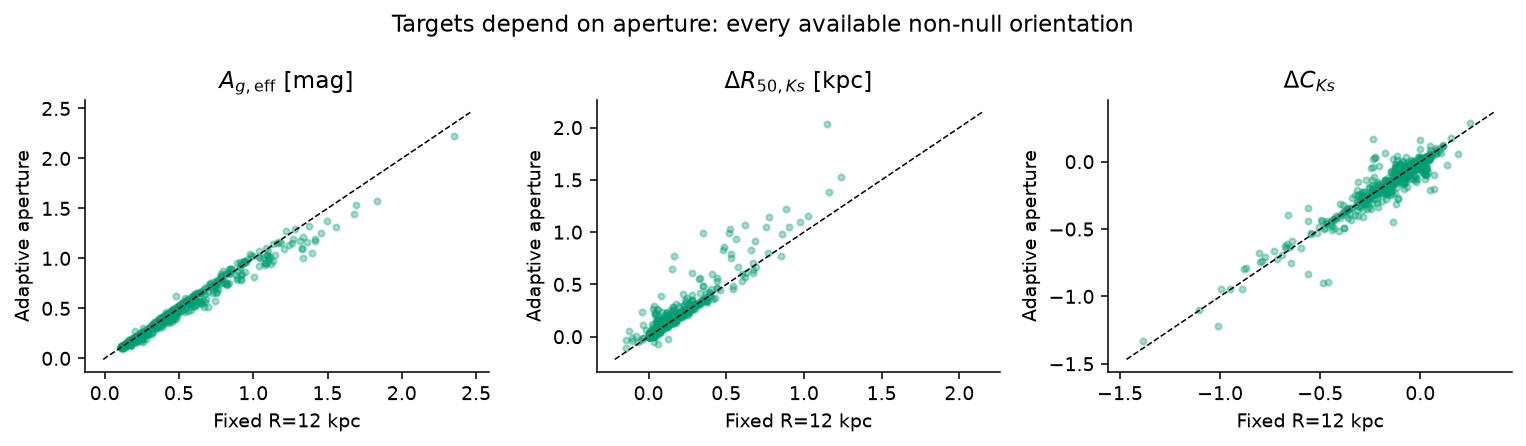

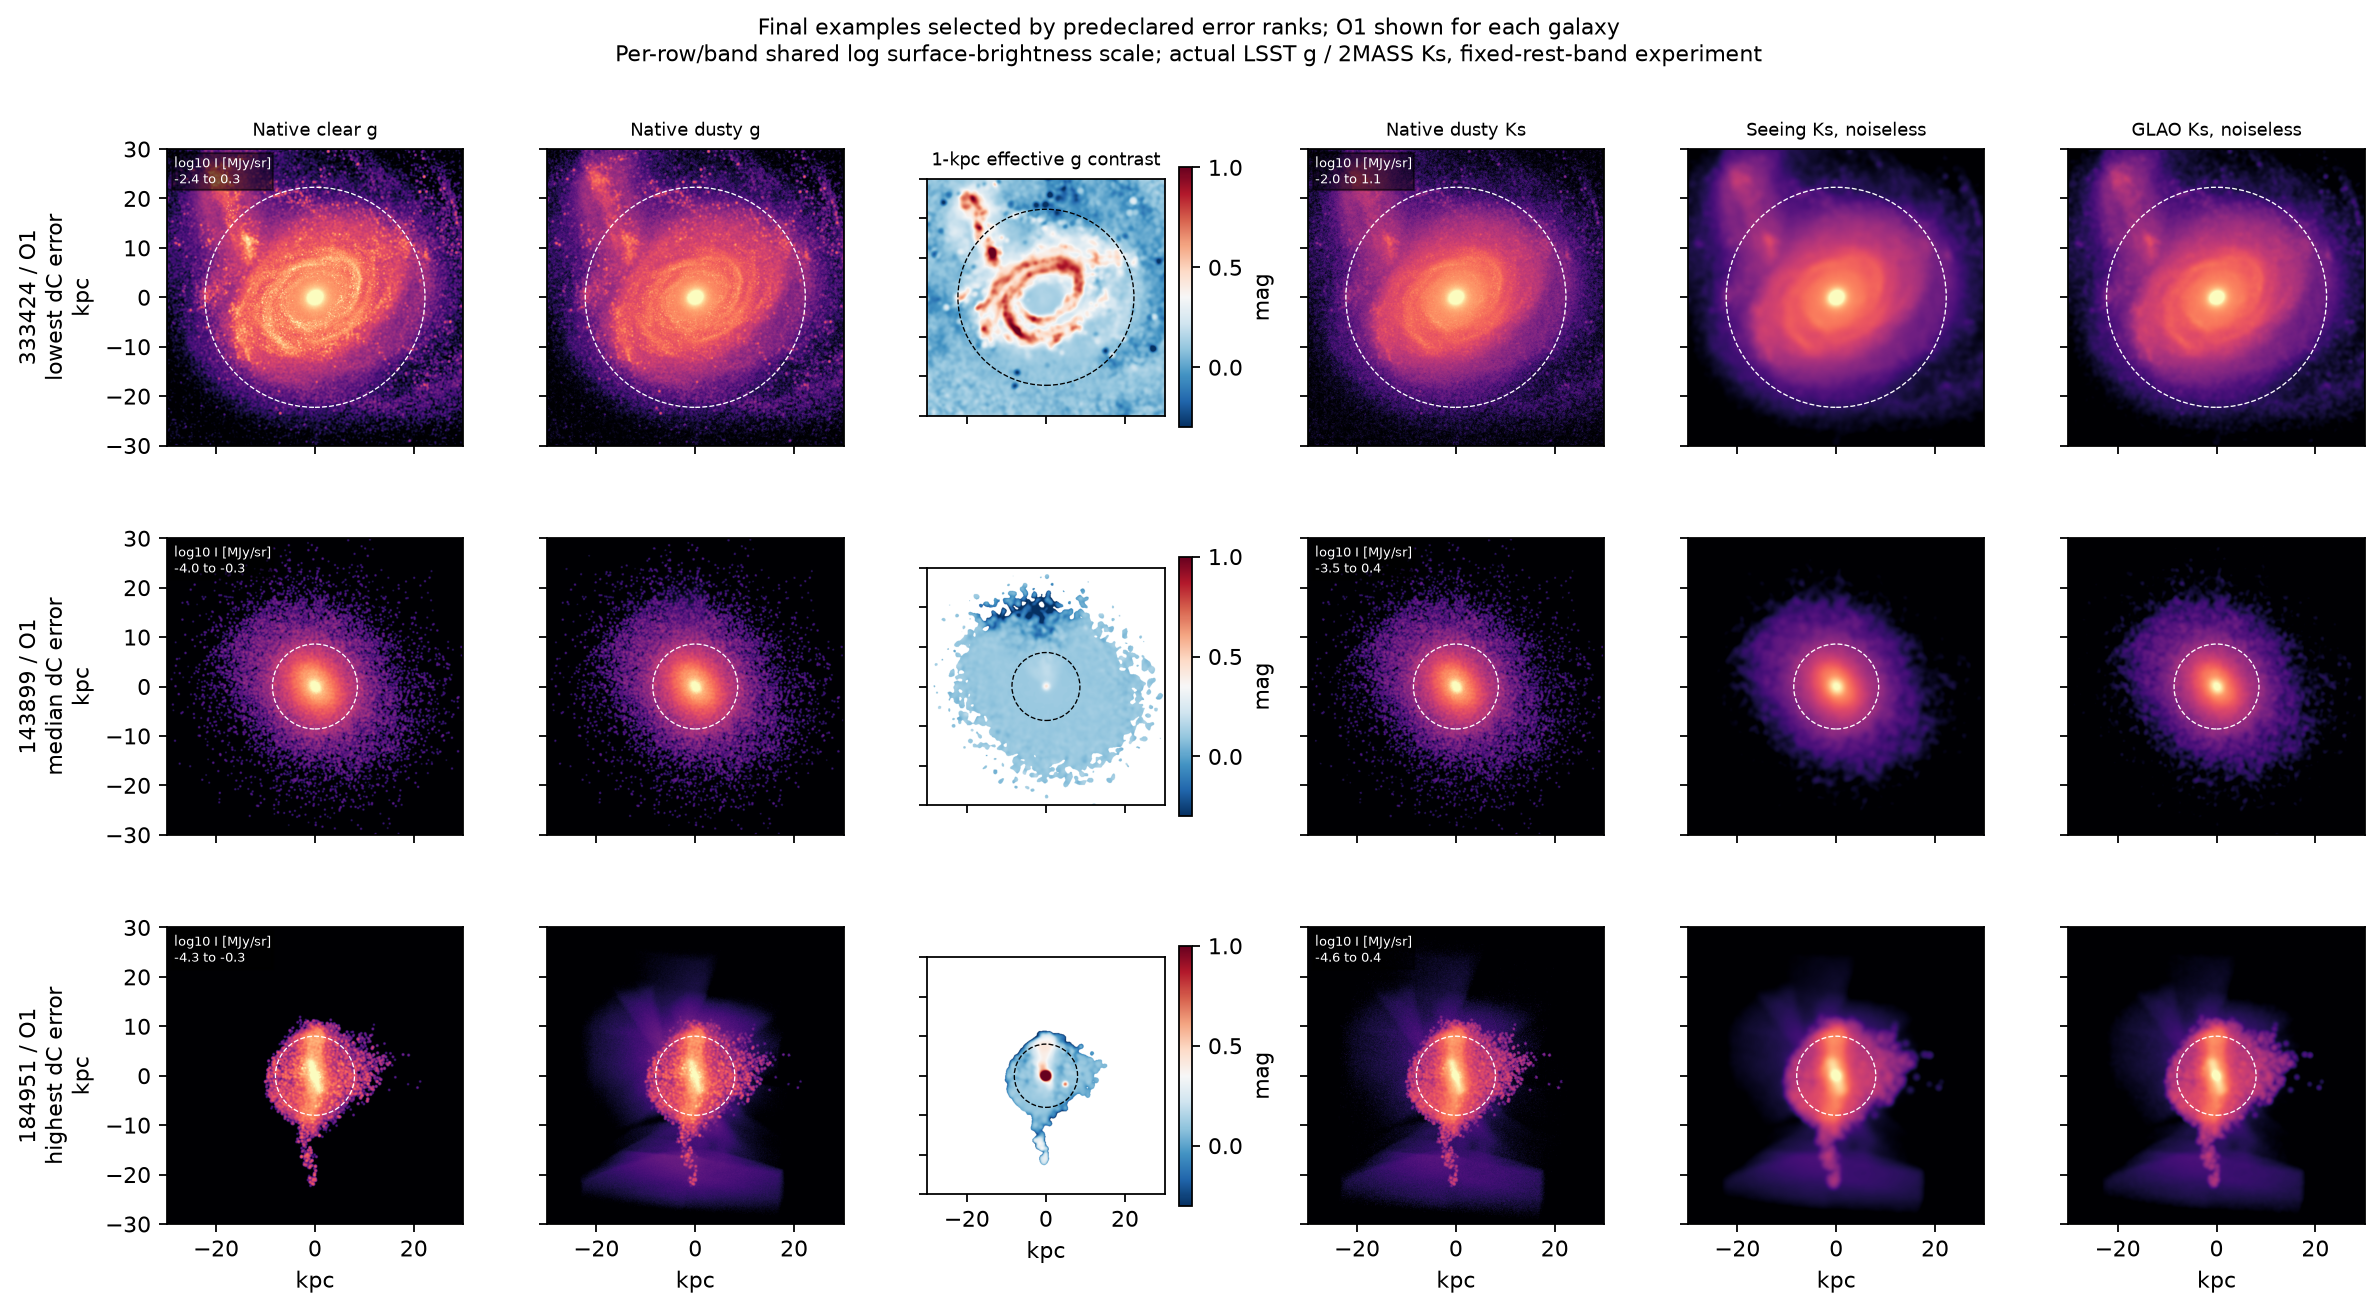

In [7]:
display(pd.read_csv(O/'instrument_stress_predictions_summary.csv').query("target in ['A_g','dR50_Ks','dC_Ks']")[["evaluation","scenario","target","MAE"]])
display(pd.read_csv(O/'shift_and_noise_predictions_summary.csv').query("target in ['A_g','dR50_Ks','dC_Ks']")[["evaluation","scenario","family","target","MAE"]])
display(Image(filename=str(O/'figures/aperture_target_sensitivity.png')))
display(Image(filename=str(O/'figures/representative_success_and_failure_images.png')))

In [8]:
display(Markdown((O/'workshop_summary.md').read_text()))
print('Replay complete; no final refit, tuning, or second final inference.')

# Beyond the Foreground Screen — workshop results

**120 verified galaxies;74 development fits,13 calibration galaxies;16 untouched positive-dust final galaxies plus4 final source controls.** Frozen86/14/20 assignments, grouped5-fold development selection, one final evaluation; four noise draws×five correlated views per galaxy.

Operational DR1 contrasts, **not yet calibrated physical attenuation**. Four exact-zero-dust source controls retain≈0.12-mag g offsets; no global subtraction. No unique3D geometry recovery.

| target | constant | phot_seeing | seeing | GLAO |
|---|---|---|---|---|
| A_g | 0.3003 | 0.0794 | 0.0734 | 0.0741 |
| A_g_p50_1kpc | 0.0522 | 0.0497 | 0.0441 | 0.0441 |
| dR50_Ks | 0.1282 | 0.0992 | 0.0777 | 0.0799 |
| dC_Ks | 0.1521 | 0.1174 | 0.0887 | 0.0887 |

Values are equal-galaxy MAE. Magnitudes/kpc/dimensionless concentration as appropriate. Recommended models were selected before final access, not by final scores. Constants and photometry remain essential baselines. Paired95% gain intervals are in `workshop_key_numbers.csv` and the gain figure.

None of the eight recommended-model final paired GLAO-gain intervals excludes zero on the positive side. Intervals support adverse effects for dR50_g.

TaskB corrections and PSF transfer must be separated: see `scientific_report.md` and native-clear corrected errors. Concentration is center-sensitive; a0.5-kpc offset changes ΔC materially. GLAO preserving morphology does not establish identification of individual dust structures.

**Slides:** `figures/model_and_observing_strategy_comparison.png`, `paired_GLAO_gains.png`, `prediction_vs_atlas_target.png`, `learning_curves.png`, `representative_success_and_failure_images.png`. PDF counterparts are available.

**Honest conclusion:** workshop-ready as a conditional benchmark with negative results and source controls. Physical-dust/ULTIMATE publication requires source-label calibration, realistic observer-frame/instrument validation and independent domain-transfer tests. HAWK-I informs nuisance tests, not dust truth or a calibrated ULTIMATE PSF. The final20 is now used and must not be retuned upon.


Replay complete; no final refit, tuning, or second final inference.
